## When environment is slippery
4x4 grid world with 80% chances of moving in intented direction, 10% slip left and, 10% slip right.
Agent starts at 00.
01, 20, 30, and 22 are pit.
33 is goal state.

In [ ]:
import random
import torch
import torch.nn.functional as F
import torch.optim as optim

# Grid setup: 4 rows, 4 columns
# Start: (0,0) | Goal: (3,3)
# Pits: (0,1), (2,0), (3,0), (2,2)
# Actions: 0=Up, 1=Right, 2=Down, 3=Left

# Create a tabular policy: a 4x4 grid where each cell has 4 action logits (scores)
policy_logits = torch.zeros((4, 4, 4), requires_grad=True)

# Use standard Adam optimizer to update the policy
optimizer = optim.Adam([policy_logits], lr=0.1)

# --- 1. Offline Preference Dataset ---
# A winning path navigates safely to (3,3):
# (0,0) Down -> (1,0) Right -> (1,1) Right -> (1,2) Right -> (1,3) Down -> (2,3) Down -> (3,3)
dataset = [
    # Original paths
    {"winner": [(0,0, 2), (1,0, 1), (1,1, 1), (1,2, 1), (1,3, 2), (2,3, 2)], "loser": [(0,0, 1)]},
    {"winner": [(1,0, 1), (1,1, 1), (1,2, 1), (1,3, 2), (2,3, 2)], "loser": [(1,0, 2)]},
    {"winner": [(1,2, 1), (1,3, 2), (2,3, 2)], "loser": [(1,2, 2)]},
    {"winner": [(2,1, 2), (3,1, 1), (3,2, 1)], "loser": [(2,1, 1)]},
    {"winner": [(2,1, 2), (3,1, 1), (3,2, 1)], "loser": [(2,1, 3)]},
    {"winner": [(0,0, 2)], "loser": [(0,0, 0)]},
    {"winner": [(0,0, 2)], "loser": [(0,0, 3)]},

    # Alternate path through the middle
    {"winner": [(0,0, 2), (1,0, 1), (1,1, 2), (2,1, 2), (3,1, 1), (3,2, 1)], "loser": [(0,0, 1)]},
    {"winner": [(1,1, 2), (2,1, 2), (3,1, 1), (3,2, 1)], "loser": [(1,1, 0)]},

    # --- NEW RECOVERY PATHS ---
    # Recovery from (0,2): Optimal is Right (1) to (0,3). Loser is Left (3) which goes into the (0,1) pit.
    {"winner": [(0,2, 1), (0,3, 2), (1,3, 2), (2,3, 2)], "loser": [(0,2, 3)]},
    {"winner": [(0,2, 1), (0,3, 2), (1,3, 2), (2,3, 2)], "loser": [(0,2, 0)]},

    # Recovery from (0,3): Optimal is Down (2) to (1,3). Loser is Left (3) which moves away from the goal, or Right (1) which hits the wall.
    {"winner": [(0,3, 2), (1,3, 2), (2,3, 2)], "loser": [(0,3, 3)]},
    {"winner": [(0,3, 2), (1,3, 2), (2,3, 2)], "loser": [(0,3, 1)]},
]

# Helper function to calculate the total log probability of a trajectory
def get_trajectory_log_prob(trajectory):
    log_prob_sum = 0
    for row, col, action in trajectory:
        log_probs = F.log_softmax(policy_logits[row, col], dim=0)
        log_prob_sum += log_probs[action]
    return log_prob_sum, len(trajectory)

# --- 2. SimPO Training Loop ---
beta = 2.0   # Scaling factor
gamma = 1  # Target reward margin
epochs = 150

for epoch in range(epochs):
    total_loss = 0
    for data in dataset:
        log_p_winner, len_winner = get_trajectory_log_prob(data["winner"])
        log_p_loser, len_loser = get_trajectory_log_prob(data["loser"])

        # SimPO Length-Normalized Rewards (corrected with multiplication)
        reward_winner = (beta / len_winner) * log_p_winner
        reward_loser = (beta / len_loser) * log_p_loser

        # SimPO Margin and Loss Calculation
        reward_difference = reward_winner - reward_loser - gamma
        loss = -F.logsigmoid(reward_difference)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1} | Loss: {total_loss:.4f}")

# --- 3. Evaluate the Learned Policy for ALL Cells ---
action_names = {0: "Up", 1: "Right", 2: "Down", 3: "Left"}
print("\nLearned Policy Probabilities for All Cells:")

# Updated to iterate over 4x4 grid
for row in range(4):
    for col in range(4):
        probs = F.softmax(policy_logits[row, col], dim=0)

        up_p = probs[0].item() * 100
        right_p = probs[1].item() * 100
        down_p = probs[2].item() * 100
        left_p = probs[3].item() * 100

        print(f"State ({row},{col}): "
              f"Up: {up_p:>5.1f}% | "
              f"Right: {right_p:>5.1f}% | "
              f"Down: {down_p:>5.1f}% | "
              f"Left: {left_p:>5.1f}%")

# --- 4. Slippery Environment Rollout ---
current_state = (0, 0)
goal_state = (3, 3)
pits = [(0, 1), (2, 0), (3, 0), (2, 2)]
path = [current_state]

max_steps = 25

print(f"\nStarting slippery journey from {current_state} to {goal_state}...")

for step in range(max_steps):
    row, col = current_state

    if current_state == goal_state:
        print(f"Success! Goal reached in {step} steps.")
        break
    if current_state in pits:
        print("Failed! Fell into a pit.")
        break

    intended_action = torch.argmax(policy_logits[row, col]).item()

    roll = random.random()
    if roll < 0.8:
        actual_action = intended_action
    elif roll < 0.9:
        actual_action = (intended_action - 1) % 4
    else:
        actual_action = (intended_action + 1) % 4

    intended_name = action_names[intended_action]
    actual_name = action_names[actual_action]

    # Updated grid bounds checking to maximum index 3
    next_row, next_col = row, col
    if actual_action == 0:   # Up
        next_row = max(row - 1, 0)
    elif actual_action == 1: # Right
        next_col = min(col + 1, 3)
    elif actual_action == 2: # Down
        next_row = min(row + 1, 3)
    elif actual_action == 3: # Left
        next_col = max(col - 1, 0)

    current_state = (next_row, next_col)
    path.append(current_state)

    if intended_action == actual_action:
        print(f"Step {step + 1}: Intended '{intended_name}' -> Successfully moved to {current_state}")
    else:
        print(f"Step {step + 1}: Intended '{intended_name}' -> Slipped and went '{actual_name}' to {current_state}")

print("\nFinal Path Coordinates:")
print(path)

Epoch 50 | Loss: 0.0131
Epoch 100 | Loss: 0.0041
Epoch 150 | Loss: 0.0020

Learned Policy Probabilities for All Cells:
State (0,0): Up:   0.9% | Right:   0.4% | Down:  97.8% | Left:   0.9%
State (0,1): Up:  25.0% | Right:  25.0% | Down:  25.0% | Left:  25.0%
State (0,2): Up:   0.4% | Right:  22.4% | Down:  76.7% | Left:   0.4%
State (0,3): Up:   5.8% | Right:   0.6% | Down:  93.0% | Left:   0.6%
State (1,0): Up:  13.2% | Right:  73.0% | Down:   0.7% | Left:  13.2%
State (1,1): Up:   0.5% | Right:  70.1% | Down:  24.5% | Left:   4.9%
State (1,2): Up:   8.0% | Right:  83.2% | Down:   0.7% | Left:   8.0%
State (1,3): Up:   1.8% | Right:   1.8% | Down:  94.5% | Left:   1.8%
State (2,0): Up:  25.0% | Right:  25.0% | Down:  25.0% | Left:  25.0%
State (2,1): Up:  24.2% | Right:   0.7% | Down:  74.4% | Left:   0.7%
State (2,2): Up:  25.0% | Right:  25.0% | Down:  25.0% | Left:  25.0%
State (2,3): Up:   1.8% | Right:   1.8% | Down:  94.5% | Left:   1.8%
State (3,0): Up:  25.0% | Right:  25.0% |

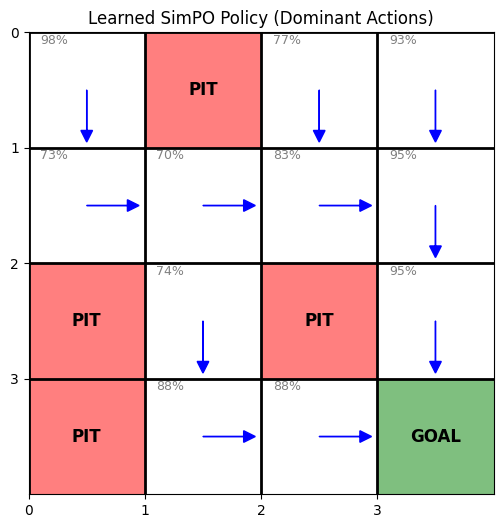

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

grid_size = 4
pits = [(0, 1), (2, 0), (3, 0), (2, 2)]
goal = (3, 3)

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(0, grid_size)
ax.set_ylim(0, grid_size)
ax.set_xticks(np.arange(0, grid_size, 1))
ax.set_yticks(np.arange(0, grid_size, 1))
ax.grid(color='black', linestyle='-', linewidth=2)
ax.invert_yaxis() # Match matrix (row, col) layout

# Action mappings to vector directions (dx, dy)
# 0=Up (0,-1), 1=Right (1,0), 2=Down (0,1), 3=Left (-1,0)
action_vectors = {0: (0, -0.35), 1: (0.35, 0), 2: (0, 0.35), 3: (-0.35, 0)}

for row in range(grid_size):
    for col in range(grid_size):
        state = (row, col)

        # Color pits and goal
        if state in pits:
            ax.add_patch(plt.Rectangle((col, row), 1, 1, facecolor='red', alpha=0.5))
            ax.text(col + 0.5, row + 0.5, 'PIT', ha='center', va='center', fontsize=12, weight='bold')
            continue
        elif state == goal:
            ax.add_patch(plt.Rectangle((col, row), 1, 1, facecolor='green', alpha=0.5))
            ax.text(col + 0.5, row + 0.5, 'GOAL', ha='center', va='center', fontsize=12, weight='bold')
            continue

        # Get dominant action
        probs = F.softmax(policy_logits[row, col], dim=0)
        best_action = torch.argmax(probs).item()
        prob_val = probs[best_action].item() * 100

        dx, dy = action_vectors[best_action]

        # Draw arrow for the highest probability action
        ax.arrow(col + 0.5, row + 0.5, dx, dy, head_width=0.1, head_length=0.1, fc='blue', ec='blue')
        ax.text(col + 0.1, row + 0.1, f"{prob_val:.0f}%", fontsize=9, color='gray')

plt.title("Learned SimPO Policy (Dominant Actions)")
plt.show()